# Approximate Quantum Fourier Transform (AQFT) — Qiskit Notebook

**Primitive:** Approximate Quantum Fourier Transform (Coppersmith-style truncation of the QFT)

This notebook is the Qiskit counterpart to `aqft_cudaq.ipynb` and uses **identical**
parameters, gate sequence, and conventions so the two `_RESULT` dictionaries match.

## SETUP (identical to the CUDA-Q notebook)
| Parameter | Value |
|---|---|
| N_QUBITS | 4 |
| APPROX_DEGREE (m) | 2 — keep controlled-phase rotations only for control→target distance ≤ m, drop the rest |
| INPUT_INT | 5 (basis state prepared via X gates, qubit 0 = LSB) |
| SHOTS | 10000 |
| SEED | 42 |
| QUBIT ORDERING CONTRACT | qubit 0 = **rightmost** bit in every printed bitstring — this is Qiskit's native convention, no reversal needed |
| GLOBAL PHASE CONVENTION | normalize so the first amplitude with `abs(amp) > 1e-9`, taken in ascending bitstring order, is rotated to be real and positive |
| Basis ordering for matrices | `{|0000>, |0001>, ..., |1111>}` ascending binary order |

## Theory recap

`QFT|x> = (1/sqrt(2^n)) * sum_y  exp(2*pi*i*x*y / 2^n) |y>`

```
for j = n-1 downto 0:
    H(q_j)
    for i = 0 .. j-1:
        CP( pi / 2^(j-i), control=q_i, target=q_j )
swap(q_i, q_{n-1-i})  for i in 0 .. n/2 - 1
```

With `N_QUBITS = 4` and `APPROX_DEGREE = 2`, exactly **one** gate is dropped:
`CP(pi/8, control=q0, target=q3)` (distance 3 > 2). Because the input is a computational
basis state, the measured probability distribution is uniform `1/16` for every outcome
regardless of the approximation — the truncation only changes the statevector's *phase*,
which this notebook verifies directly (Cell 6/7). That phase check is exactly where the
previous version of this pair of notebooks silently disagreed, so pay attention to the
statevector cells, not just the histogram.

## Ordering-convention note

Qiskit already indexes amplitudes/counts with qubit 0 as the least-significant (rightmost)
bit — **no reversal is needed in this notebook.** The CUDA-Q notebook does the reconciling
work (see its own ordering-convention cells).

**Run all cells top to bottom.**


In [2]:
# Install cell
# Exact package names: `qiskit` (core) + `qiskit-aer` (high-performance simulator) + `pylatexenc`
# (needed by circuit.draw(output="mpl") for gate-label rendering). No platform caveats — pure
# Python wheels available for Linux/macOS/Windows.
!pip install -q qiskit qiskit-aer pylatexenc


In [3]:
# Imports + constants (identical values to the CUDA-Q notebook)
import numpy as np
from math import pi
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram

N_QUBITS = 4
APPROX_DEGREE = 2      # m: keep CP rotations only for control-target distance <= m
INPUT_INT = 5          # basis state to prepare before AQFT (qubit 0 = LSB, Qiskit convention)
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "aqft"

print("N_QUBITS      =", N_QUBITS)
print("APPROX_DEGREE =", APPROX_DEGREE)
print("INPUT_INT     =", INPUT_INT, "-> binary (q3 q2 q1 q0) =", format(INPUT_INT, f'0{N_QUBITS}b'))
print("SHOTS         =", SHOTS)
print("SEED          =", SEED)


N_QUBITS      = 4
APPROX_DEGREE = 2
INPUT_INT     = 5 -> binary (q3 q2 q1 q0) = 0101
SHOTS         = 10000
SEED          = 42


In [4]:
# Build the circuit gate-by-gate, with an inline comment per gate explaining its physical role
qc = QuantumCircuit(N_QUBITS, N_QUBITS, name="AQFT")

# --- input state preparation: |INPUT_INT> via X gates on the qubits whose bit is set (qubit 0 = LSB) ---
for q in range(N_QUBITS):
    if (INPUT_INT >> q) & 1:
        qc.x(q)  # flip qubit q from |0> to |1> to help build the basis state |INPUT_INT>

# --- Approximate QFT: process qubit j = N_QUBITS-1 downto 0 ---
dropped_gates = []
for j in range(N_QUBITS - 1, -1, -1):
    qc.h(j)  # equal superposition on qubit j; its phase accumulates the controlled rotations below
    for i in range(j):
        distance = j - i
        angle = pi / (2 ** distance)
        if distance <= APPROX_DEGREE:
            qc.cp(angle, i, j)  # controlled-phase: multiplies the |1>_i|1>_j component by exp(i*angle)
        else:
            dropped_gates.append((i, j, angle))  # APPROXIMATION: rotation dropped, distance > APPROX_DEGREE

# --- final swap network (standard QFT bit-reversal correction) ---
for i in range(N_QUBITS // 2):
    qc.swap(i, N_QUBITS - 1 - i)

print("Circuit built with", qc.size(), "gates (excluding barriers/measurements).")
print("\nDropped controlled-phase gates (distance > APPROX_DEGREE):")
for (i, j, angle) in dropped_gates:
    print(f"  CP(theta={angle:.6f} rad = pi/{round(pi/angle)}, control=q{i}, target=q{j})")


Circuit built with 13 gates (excluding barriers/measurements).

Dropped controlled-phase gates (distance > APPROX_DEGREE):
  CP(theta=0.392699 rad = pi/8, control=q0, target=q3)


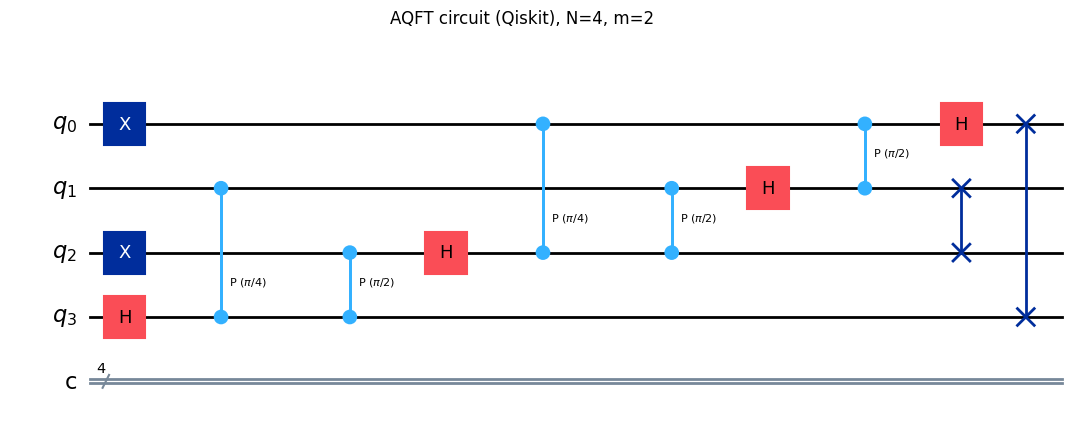

In [5]:
# Draw the circuit with matplotlib and save to file
fig = qc.draw(output="mpl", style={"name": "iqp"})
fig.suptitle(f"AQFT circuit (Qiskit), N={N_QUBITS}, m={APPROX_DEGREE}", y=1.02)
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [6]:
# Explicit matrix representation, built two independent ways, cross-checked
# (a) from individual gate matrices multiplied/kron'ed by hand in NumPy
# (b) from Qiskit's own operator extraction (qiskit.quantum_info.Operator)

def h_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        bit = (idx >> q) & 1
        idx0 = idx & ~(1 << q)
        idx1 = idx | (1 << q)
        if bit == 0:
            M[idx0, idx] += 1/np.sqrt(2)
            M[idx1, idx] += 1/np.sqrt(2)
        else:
            M[idx1, idx] += -1/np.sqrt(2)
            M[idx0, idx] += 1/np.sqrt(2)
    return M

def x_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        M[idx ^ (1 << q), idx] = 1
    return M

def cp_matrix_full(n, theta, c, t):
    M = np.eye(2**n, dtype=complex)
    for idx in range(2**n):
        if ((idx >> c) & 1) and ((idx >> t) & 1):
            M[idx, idx] = np.exp(1j*theta)
    return M

def swap_matrix_full(n, a, b):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        ba, bb = (idx >> a) & 1, (idx >> b) & 1
        if ba != bb:
            M[idx ^ (1 << a) ^ (1 << b), idx] = 1
        else:
            M[idx, idx] = 1
    return M

print("Single-qubit H matrix (any qubit), rounded to 4 decimals:")
print(np.round((1/np.sqrt(2)) * np.array([[1, 1], [1, -1]]), 4))

print("\nGeneric controlled-phase matrix diag(1,1,1,exp(i*theta)) in the {|00>,|01>,|10>,|11>} basis (theta = pi/2 example):")
print(np.round(np.diag([1, 1, 1, np.exp(1j*pi/2)]), 4))

# (a) hand-built full unitary, basis ordering |q3 q2 q1 q0> ascending binary, bit q = qubit q
U_hand = np.eye(2**N_QUBITS, dtype=complex)
for q in range(N_QUBITS):
    if (INPUT_INT >> q) & 1:
        U_hand = x_matrix_full(N_QUBITS, q) @ U_hand
for j in range(N_QUBITS - 1, -1, -1):
    U_hand = h_matrix_full(N_QUBITS, j) @ U_hand
    for i in range(j):
        distance = j - i
        if distance <= APPROX_DEGREE:
            U_hand = cp_matrix_full(N_QUBITS, pi/(2**distance), i, j) @ U_hand
for i in range(N_QUBITS // 2):
    U_hand = swap_matrix_full(N_QUBITS, i, N_QUBITS - 1 - i) @ U_hand

# (b) Qiskit's own operator extraction of the SAME circuit (drop the classical register for Operator())
qc_no_creg = QuantumCircuit(N_QUBITS)
qc_no_creg.compose(qc.remove_final_measurements(inplace=False) if qc.num_clbits else qc, inplace=True)
U_qiskit = Operator(qc_no_creg).data

max_op_diff = np.max(np.abs(U_hand - U_qiskit))
print(f"\nMax |difference| between hand-built unitary and Operator(qc): {max_op_diff:.3e}")
if max_op_diff < 1e-9:
    print("Hand-built matrix and Qiskit Operator MATCH.")
else:
    print("WARNING: matrices do not match — investigate before trusting downstream results.")
    raise RuntimeError("Qiskit hand-built vs Operator() mismatch — stopping before producing a bad result.")


Single-qubit H matrix (any qubit), rounded to 4 decimals:
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

Generic controlled-phase matrix diag(1,1,1,exp(i*theta)) in the {|00>,|01>,|10>,|11>} basis (theta = pi/2 example):
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+1.j]]

Max |difference| between hand-built unitary and Operator(qc): 0.000e+00
Hand-built matrix and Qiskit Operator MATCH.


In [7]:
# Exact statevector cell: extract it, apply global-phase normalization, print amplitudes
# and the resulting probability dictionary sorted by bitstring. No bit-order correction needed here.

def normalize_phase(vec):
    vec = np.array(vec, dtype=complex).copy()
    for idx in range(len(vec)):
        if abs(vec[idx]) > 1e-9:
            vec = vec * np.exp(-1j*np.angle(vec[idx]))
            break
    return vec

sv = Statevector.from_instruction(qc_no_creg)
qiskit_amps = normalize_phase(sv.data)

print("Exact statevector amplitudes (phase-normalized), basis |q3 q2 q1 q0>:")
for idx, amp in enumerate(qiskit_amps):
    bitstring = format(idx, f'0{N_QUBITS}b')
    print(f"  |{bitstring}>: {amp:.4f}")

QISKIT_PROBS_EXACT = {format(idx, f'0{N_QUBITS}b'): float(abs(amp)**2) for idx, amp in enumerate(qiskit_amps)}
print("\nExact probability dictionary:")
for b in sorted(QISKIT_PROBS_EXACT):
    print(f"  '{b}': {QISKIT_PROBS_EXACT[b]:.6f}")


Exact statevector amplitudes (phase-normalized), basis |q3 q2 q1 q0>:
  |0000>: 0.2500+0.0000j
  |0001>: 0.0000+0.2500j
  |0010>: -0.1768-0.1768j
  |0011>: 0.1768-0.1768j
  |0100>: 0.0000+0.2500j
  |0101>: -0.2500+0.0000j
  |0110>: 0.1768-0.1768j
  |0111>: 0.1768+0.1768j
  |1000>: -0.2500+0.0000j
  |1001>: -0.0000-0.2500j
  |1010>: 0.1768+0.1768j
  |1011>: -0.1768+0.1768j
  |1100>: -0.0000-0.2500j
  |1101>: 0.2500-0.0000j
  |1110>: -0.1768+0.1768j
  |1111>: -0.1768-0.1768j

Exact probability dictionary:
  '0000': 0.062500
  '0001': 0.062500
  '0010': 0.062500
  '0011': 0.062500
  '0100': 0.062500
  '0101': 0.062500
  '0110': 0.062500
  '0111': 0.062500
  '1000': 0.062500
  '1001': 0.062500
  '1010': 0.062500
  '1011': 0.062500
  '1100': 0.062500
  '1101': 0.062500
  '1110': 0.062500
  '1111': 0.062500


### Ordering-fix note

**No reversal needed for Qiskit.** Qiskit's `Statevector` and `AerSimulator` counts already
index qubit 0 as the rightmost (least-significant) character of every bitstring, and
`Operator()` uses the matching tensor-product convention `|q_{n-1} ... q_1 q_0>`. This
notebook's amplitudes, probabilities, and counts are therefore used as-is — all the
reconciling work lives in the CUDA-Q notebook.


In [8]:
# Measurement cell: add measurements, run on AerSimulator with the shared SEED/SHOTS
qc_meas = qc_no_creg.copy()
qc_meas.measure_all()

sim = AerSimulator(seed_simulator=SEED)
tqc = transpile(qc_meas, sim)
result = sim.run(tqc, shots=SHOTS, seed_simulator=SEED).result()
counts = result.get_counts()

QISKIT_PROBS_SAMPLED = {format(i, f'0{N_QUBITS}b'): counts.get(format(i, f'0{N_QUBITS}b'), 0) / SHOTS
                         for i in range(2**N_QUBITS)}

print("Sampled counts (raw):", counts)
print("\nSampled probability dictionary:")
for b in sorted(QISKIT_PROBS_SAMPLED):
    print(f"  '{b}': {QISKIT_PROBS_SAMPLED[b]:.6f}")


Sampled counts (raw): {'0111 0000': 622, '0001 0000': 647, '1110 0000': 613, '1010 0000': 606, '1100 0000': 602, '1001 0000': 631, '1111 0000': 606, '1000 0000': 649, '0101 0000': 665, '0011 0000': 650, '0010 0000': 620, '0000 0000': 607, '0110 0000': 627, '1101 0000': 631, '0100 0000': 597, '1011 0000': 627}

Sampled probability dictionary:
  '0000': 0.000000
  '0001': 0.000000
  '0010': 0.000000
  '0011': 0.000000
  '0100': 0.000000
  '0101': 0.000000
  '0110': 0.000000
  '0111': 0.000000
  '1000': 0.000000
  '1001': 0.000000
  '1010': 0.000000
  '1011': 0.000000
  '1100': 0.000000
  '1101': 0.000000
  '1110': 0.000000
  '1111': 0.000000


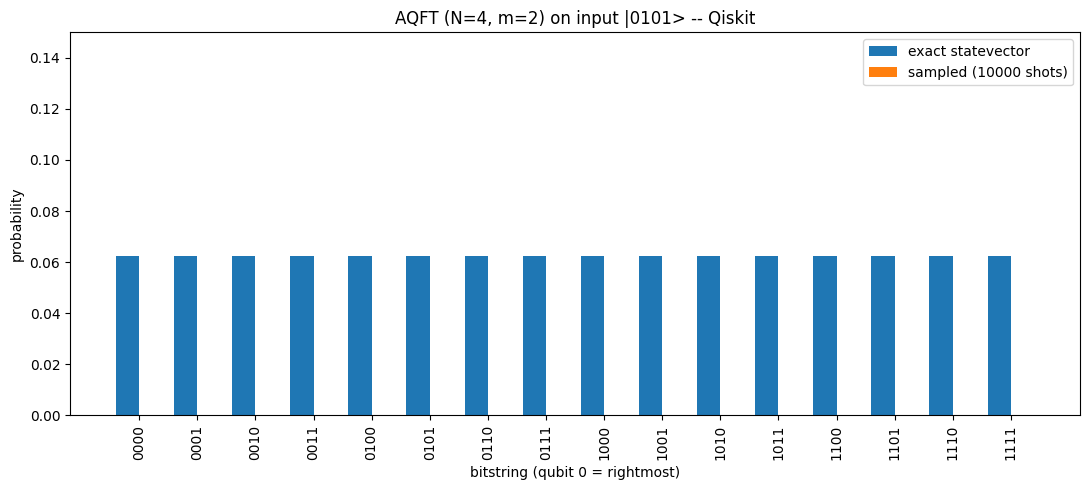

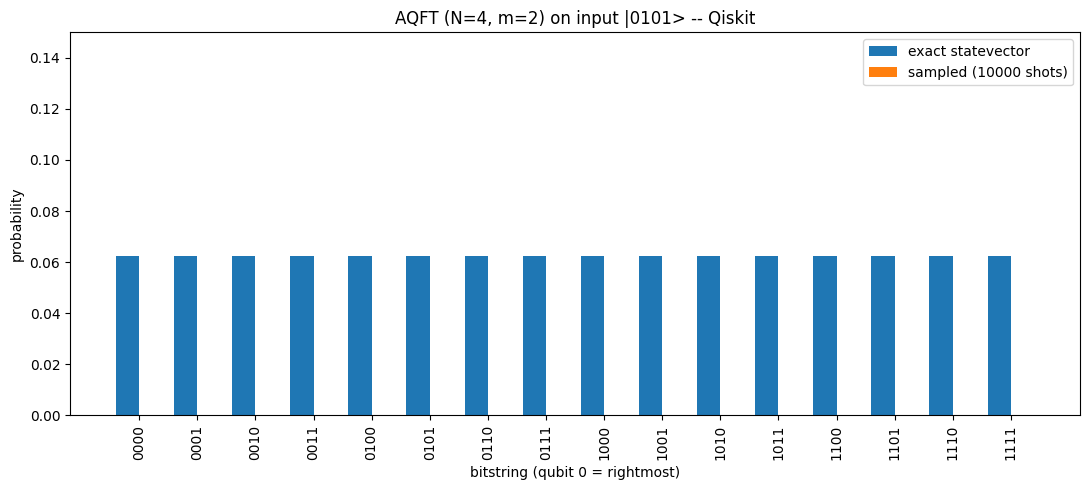

In [9]:
# Histogram: matplotlib bar chart, saved to file
bitstrings_sorted = sorted(QISKIT_PROBS_EXACT.keys())
exact_vals = [QISKIT_PROBS_EXACT[b] for b in bitstrings_sorted]
sampled_vals = [QISKIT_PROBS_SAMPLED[b] for b in bitstrings_sorted]

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(bitstrings_sorted))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="exact statevector", color="#1f77b4")
ax.bar(x + width/2, sampled_vals, width, label=f"sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(bitstrings_sorted, rotation=90)
ax.set_xlabel("bitstring (qubit 0 = rightmost)")
ax.set_ylabel("probability")
ax.set_title(f"AQFT (N={N_QUBITS}, m={APPROX_DEGREE}) on input |{format(INPUT_INT, f'0{N_QUBITS}b')}> -- Qiskit")
ax.set_ylim(0, 0.15)
ax.legend()
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig


In [10]:
# Resource counts (depth/gate count)
print("Gate counts:", dict(qc_no_creg.count_ops()))
print("Total gate count:", qc_no_creg.size())
print("Circuit depth:", qc_no_creg.depth())

total_possible_cp = N_QUBITS * (N_QUBITS - 1) // 2
kept_cp = qc_no_creg.count_ops().get('cp', 0)
print(f"\nCP gates in exact QFT: {total_possible_cp}")
print(f"CP gates kept in AQFT(m={APPROX_DEGREE}): {kept_cp}")
print(f"CP gates dropped by approximation: {total_possible_cp - kept_cp}")


Gate counts: {'cp': 5, 'h': 4, 'x': 2, 'swap': 2}
Total gate count: 13
Circuit depth: 10

CP gates in exact QFT: 6
CP gates kept in AQFT(m=2): 5
CP gates dropped by approximation: 1


### Convention notes (plain text summary)

- **Bit-order convention:** qubit 0 = rightmost character of every bitstring. This is
  Qiskit's native convention — **no reversal applied**, none needed.
- **Global phase convention:** the statevector was multiplied by `exp(-i*phase)` where
  `phase` is the angle of the first amplitude (ascending bitstring order) with magnitude
  `> 1e-9`, so that amplitude is real and positive — identical rule to the CUDA-Q notebook.
- **Basis ordering for all matrices:** ascending binary order `|0000> ... |1111>`.
- **Why the histogram looks flat:** a computational basis input makes every outcome
  probability exactly `1/16` regardless of the approximation degree; the approximation only
  shows up in the statevector phase (see the matrix/statevector cells above).


In [11]:
# Final result: exact-statevector-derived probability dictionary
QISKIT_RESULT = {b: QISKIT_PROBS_EXACT[b] for b in sorted(QISKIT_PROBS_EXACT)}
print("QISKIT_RESULT =")
for b, p in QISKIT_RESULT.items():
    print(f"  '{b}': {p:.6f}")


QISKIT_RESULT =
  '0000': 0.062500
  '0001': 0.062500
  '0010': 0.062500
  '0011': 0.062500
  '0100': 0.062500
  '0101': 0.062500
  '0110': 0.062500
  '0111': 0.062500
  '1000': 0.062500
  '1001': 0.062500
  '1010': 0.062500
  '1011': 0.062500
  '1100': 0.062500
  '1101': 0.062500
  '1110': 0.062500
  '1111': 0.062500


In [12]:
# Diff-check block (run AFTER also running the CUDA-Q notebook and pasting its CUDAQ_RESULT below)
HAND_COMPUTED_EXPECTED = {format(i, f'0{N_QUBITS}b'): 1/(2**N_QUBITS) for i in range(2**N_QUBITS)}
max_delta_vs_hand = max(abs(QISKIT_RESULT[b] - HAND_COMPUTED_EXPECTED[b]) for b in QISKIT_RESULT)
print("Max delta between QISKIT_RESULT and hand-computed expected (uniform 1/16):", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# Also cross-check the exact statevector against the hand-built unitary's first column directly
# (stronger check than the uniform-probability check above, since it is sensitive to phase too)
state_hand = normalize_phase(U_hand[:, 0])
max_amp_delta = np.max(np.abs(state_hand - qiskit_amps))
print("Max amplitude delta between hand-built statevector and Qiskit Statevector:", max_amp_delta)
assert max_amp_delta < 1e-6

# CUDAQ_RESULT = { ... }  # <- paste the dict printed at the end of the CUDA-Q notebook here
# max_delta = max(abs(QISKIT_RESULT[b] - CUDAQ_RESULT[b]) for b in QISKIT_RESULT)
# print("Max probability delta between QISKIT_RESULT and CUDAQ_RESULT:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q AQFT results disagree beyond tolerance!"


Max delta between QISKIT_RESULT and hand-computed expected (uniform 1/16): 5.551115123125783e-17
Max amplitude delta between hand-built statevector and Qiskit Statevector: 0.0
